# Household Energy Consumption — анализ и прогноз потребления электроэнергии

**Тема №4, Cluster 1: Exploratory Analytics, Time Series & Dashboards**
Команда: Rabat Karabek, Nurmukhanbet Sanzhar, Ussurbayeva Inkar — AAI-2603M

**Цель:** проанализировать суточные, недельные и сезонные паттерны нагрузки и пики потребления,
сравнить простые методы прогноза с baseline.

**Данные:** [UCI Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption) —
поминутные измерения одного дома в Со (Франция), 12.2006–11.2010, **2 075 259 строк**, 127 МБ.

| Колонка | Смысл |
|---|---|
| Global_active_power | активная мощность, кВт (минутное среднее) |
| Global_reactive_power | реактивная мощность, кВт |
| Voltage | напряжение, В |
| Global_intensity | сила тока, А |
| Sub_metering_1 | кухня (посудомойка, духовка, микроволновка), Вт·ч |
| Sub_metering_2 | прачечная (стиральная машина, сушилка, холодильник, свет), Вт·ч |
| Sub_metering_3 | бойлер и кондиционер, Вт·ч |

Логика вынесена в модули `src/*.py`, ноутбук их импортирует и показывает результаты.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, data_loader, preprocessing, timeseries, database, forecast, pipeline
from src import visualization as viz

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
config.ensure_dirs()
%matplotlib inline

## 1. Загрузка данных с учётом ограничений памяти

1. Скачиваем архив (если файла нет).
2. **Наивное чтение** `pd.read_csv` — все колонки становятся `object` (строки), т.к. пропуски обозначены `?`.
3. **Чанковое чтение** (`chunksize=500 000`): `?` → `NaN`, дата+время → `datetime64`, числа → `float32`.
4. Сохраняем результат в **Parquet**.

In [2]:
data_loader.download_dataset()

raw_naive = data_loader.read_raw_naive()
naive_mb = data_loader.memory_mb(raw_naive)
print(raw_naive.dtypes)
print(f"Naive read: {len(raw_naive):,} rows, {naive_mb:.1f} MB in memory")

Date                         str
Time                         str
Global_active_power          str
Global_reactive_power        str
Voltage                      str
Global_intensity             str
Sub_metering_1               str
Sub_metering_2               str
Sub_metering_3           float64
dtype: object
Naive read: 2,075,259 rows, 239.1 MB in memory


In [3]:
minute = data_loader.read_raw_chunked()
optimized_mb = data_loader.memory_mb(minute)
data_loader.save_parquet(minute)
print(minute.dtypes)
print(f"Chunked + float32: {len(minute):,} rows, {optimized_mb:.1f} MB in memory "
      f"(в {naive_mb / optimized_mb:.1f} раза меньше)")
del raw_naive
minute.head()

Global_active_power      float32
Global_reactive_power    float32
Voltage                  float32
Global_intensity         float32
Sub_metering_1           float32
Sub_metering_2           float32
Sub_metering_3           float32
dtype: object
Chunked + float32: 2,075,259 rows, 71.2 MB in memory (в 3.4 раза меньше)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.839996,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.630005,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.289993,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.740005,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.679993,15.8,0.0,1.0,17.0


### 1.1 Сравнение подходов к хранению/чтению (требование 9)

Baseline — наивное чтение CSV; подходы — чанковое чтение с оптимизацией типов и Parquet.
Критерии: время чтения, пиковая память процесса (RSS; каждый подход запускается в отдельном процессе), память DataFrame, размер файла.

> Наивное чтение быстрое, но даёт строки (`str`) вместо чисел — с таким фреймом нельзя считать, а пиковая память максимальная.

In [4]:
benchmark = pd.DataFrame(data_loader.benchmark_formats())
benchmark

,approach,read_time_s,peak_rss_mb,frame_memory_mb,file_size_mb,rows
0,CSV naive (baseline),0.24,614.8,239.1,126.8,2075259
1,CSV chunked + float32,2.23,310.1,71.2,126.8,2075259
2,Parquet (pyarrow),0.07,277.3,71.2,22.0,2075259


## 2. EDA: типы признаков, описательная статистика, пропуски, выбросы

In [5]:
print(f"Период: {minute.index.min()} — {minute.index.max()}")
print(f"Строк: {len(minute):,}; дубликатов меток времени: {minute.index.duplicated().sum()}")
preprocessing.feature_types(minute)

Период: 2006-12-16 17:24:00 — 2010-11-26 21:02:00
Строк: 2,075,259; дубликатов меток времени: 0


,column,dtype,feature_type,unique_values
0,Global_active_power,float32,numeric (continuous),4186
1,Global_reactive_power,float32,numeric (continuous),532
2,Voltage,float32,numeric (continuous),2837
3,Global_intensity,float32,numeric (continuous),221
4,Sub_metering_1,float32,"numeric (discrete, Wh per minute)",88
5,Sub_metering_2,float32,"numeric (discrete, Wh per minute)",81
6,Sub_metering_3,float32,"numeric (discrete, Wh per minute)",32


In [6]:
minute.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000


### 2.1 Пропуски

In [7]:
display(preprocessing.missing_report(minute))
print("Доля пропусков по годам, %:")
display(preprocessing.missing_by_year(minute).to_frame("missing_pct"))
print("Самые длинные непрерывные пропуски:")
preprocessing.longest_gaps(minute)

,missing_count,missing_pct
Global_active_power,25979,1.252
Global_reactive_power,25979,1.252
Voltage,25979,1.252
Global_intensity,25979,1.252
Sub_metering_1,25979,1.252
Sub_metering_2,25979,1.252
Sub_metering_3,25979,1.252


Доля пропусков по годам, %:


,missing_pct
datetime,
2006,0.02
2007,0.75
2008,0.03
2009,0.81
2010,3.71


Самые длинные непрерывные пропуски:


,gap_start,gap_end,missing_minutes,missing_hours
0,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,120.4
1,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,87.3
2,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,62.0
3,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,55.1
4,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,52.2


### 2.2 Выбросы (IQR, boxplot)

In [8]:
preprocessing.iqr_outliers(minute)

,column,q1,q3,lower_bound,upper_bound,outliers,outliers_pct
0,Global_active_power,0.308,1.528,-1.522,3.358,94907,4.63
1,Global_reactive_power,0.048,0.194,-0.171,0.413,40420,1.97
2,Voltage,238.990,242.890,233.140,248.740,51067,2.49
3,Global_intensity,1.400,6.400,-6.100,13.900,100961,4.93
4,Sub_metering_1,0.000,0.000,0.000,0.000,169105,8.25
5,Sub_metering_2,0.000,1.000,-1.500,2.500,77151,3.76
6,Sub_metering_3,0.000,17.000,-25.500,42.500,0,0.00


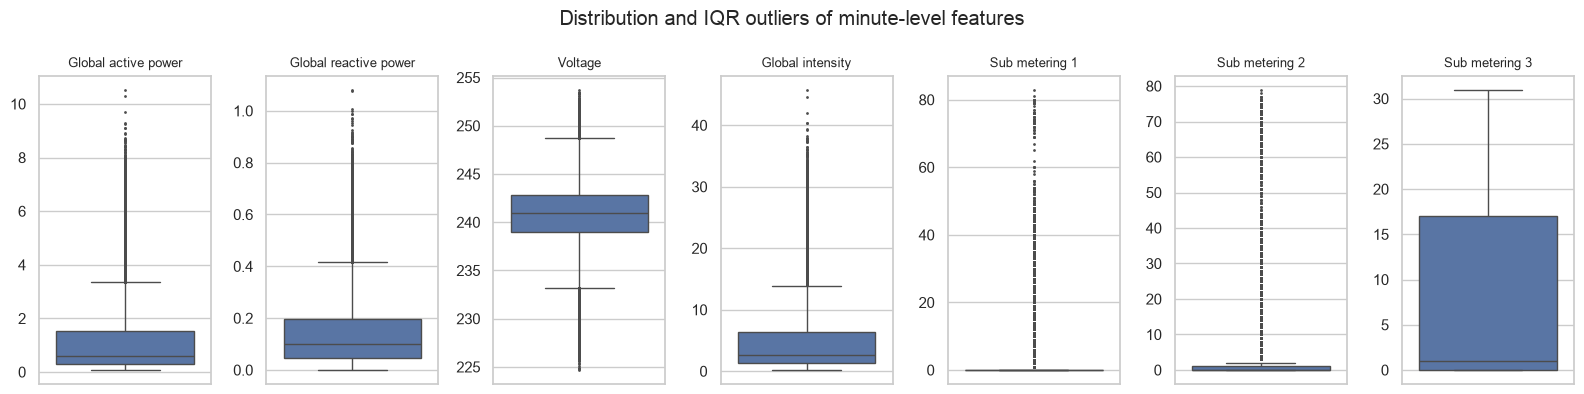

In [9]:
fig = viz.plot_boxplots(minute)

## 3. Очистка и ресемплинг

Правила очистки:
- **Выбросы не удаляем**: высокие значения мощности — это реальные пики (включение бойлера, духовки),
  именно их мы и анализируем. Sub_metering_1/2 почти всё время 0, поэтому IQR формально помечает любое включение прибора как выброс.
- **Ресемплинг минут → часы**: среднее мощности за час = кВт·ч за этот час; подсчётчики переводим в Вт·ч за час.
- Добавляем `Sub_metering_other` = общая энергия − сумма трёх подсчётчиков (всё, что не покрыто счётчиками).
- **Пропуски**: короткие (≤ 3 ч) — линейная интерполяция по времени; длинные (до 5 суток) — значение того же часа неделей раньше
  (сохраняет суточную и недельную форму ряда, в отличие от интерполяции прямой линией).

In [10]:
hourly = pipeline.build_hourly(minute)
daily = preprocessing.to_daily(hourly)
print(f"Hourly: {hourly.shape}, пропусков: {hourly.isna().sum().sum()}")
print(f"Daily:  {daily.shape}")
daily.describe().T.round(2)

Hourly: (34589, 8), пропусков: 0
Daily:  (1440, 8)


,count,mean,std,min,25%,50%,75%,max
energy_kwh,1440.0,26.13,10.01,4.17,19.49,25.82,31.57,79.56
Sub_metering_1,1440.0,1615.91,1592.80,0.00,654.25,1118.00,2225.25,11208.32
Sub_metering_2,1440.0,1867.75,2089.77,0.00,432.00,691.00,2741.14,12109.00
Sub_metering_3,1440.0,9289.20,3690.36,1288.00,6683.00,9294.50,11746.00,23743.00
Sub_metering_other,1440.0,13358.84,6099.12,2321.67,9310.43,12580.63,16501.58,61736.43
Voltage,1440.0,240.85,2.03,231.09,240.10,240.97,241.87,247.44
Global_intensity,1440.0,4.62,1.73,0.81,3.50,4.55,5.53,14.03
Global_reactive_power,1440.0,0.12,0.03,0.06,0.10,0.12,0.14,0.29


## 4. Временные ряды: скользящие средние, профили нагрузки, декомпозиция

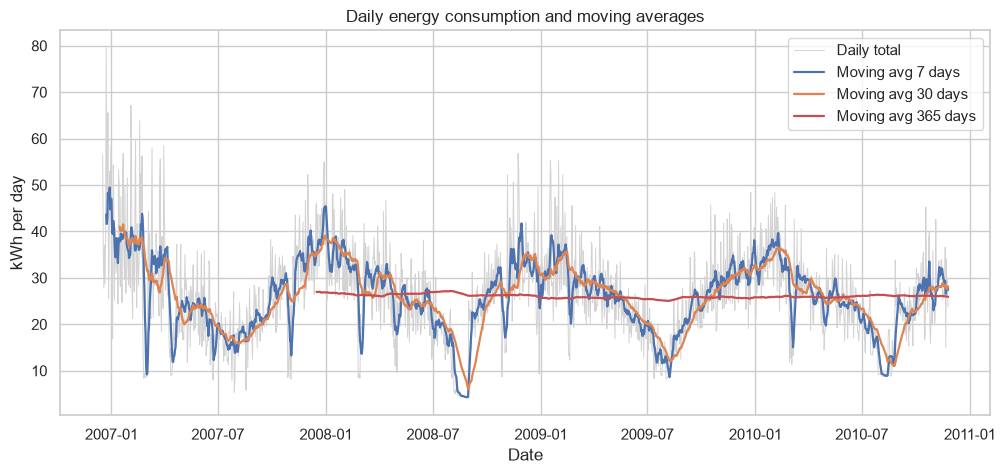

In [11]:
rolling = timeseries.rolling_means(daily)
fig = viz.plot_rolling(rolling)

,mean,median,std,max
season,,,,
autumn,27.16,26.29,7.49,56.79
spring,26.54,26.33,7.55,58.49
summer,17.37,17.84,6.72,38.15
winter,33.97,32.93,10.31,79.56


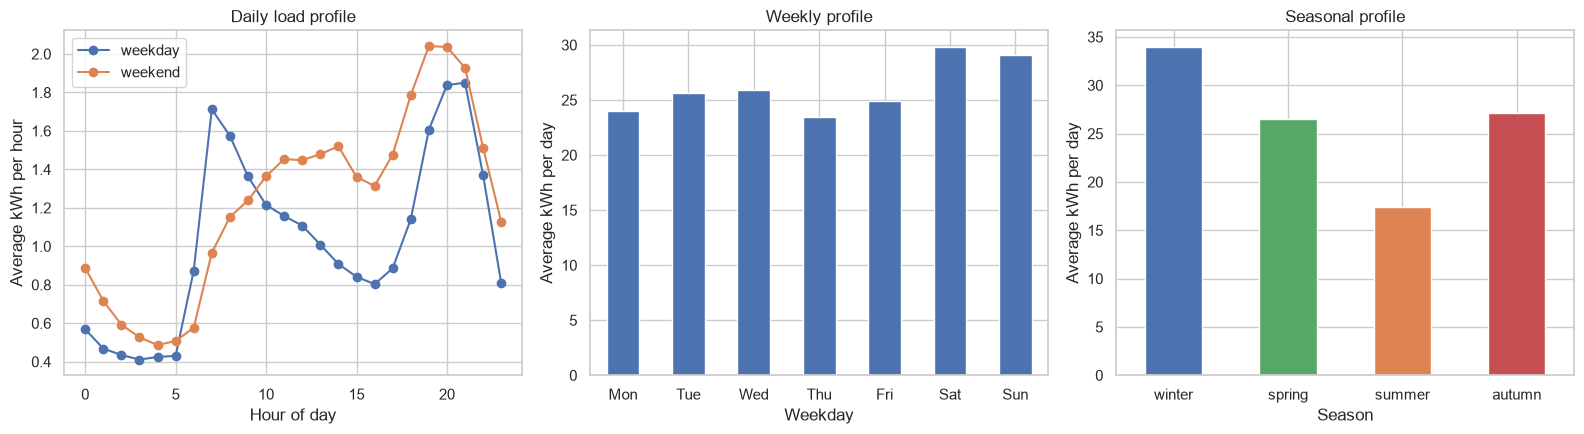

In [12]:
day_profile = timeseries.daily_profile(hourly)
week_profile = timeseries.weekly_profile(daily)
season_profile = timeseries.seasonal_profile(daily)
fig = viz.plot_profiles(day_profile, week_profile, season_profile)
display(season_profile)

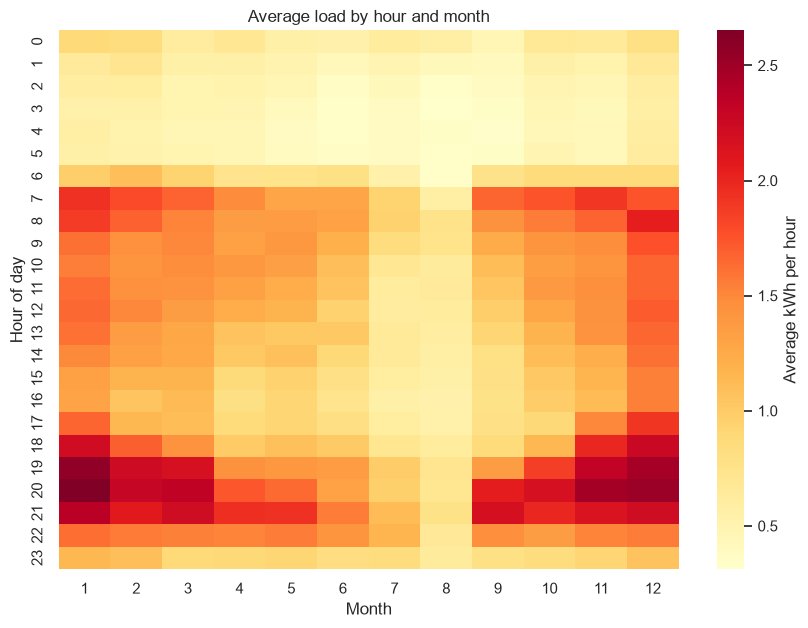

In [13]:
fig = viz.plot_hour_month_heatmap(timeseries.heatmap_hour_month(hourly))

### 4.1 Сезонная декомпозиция

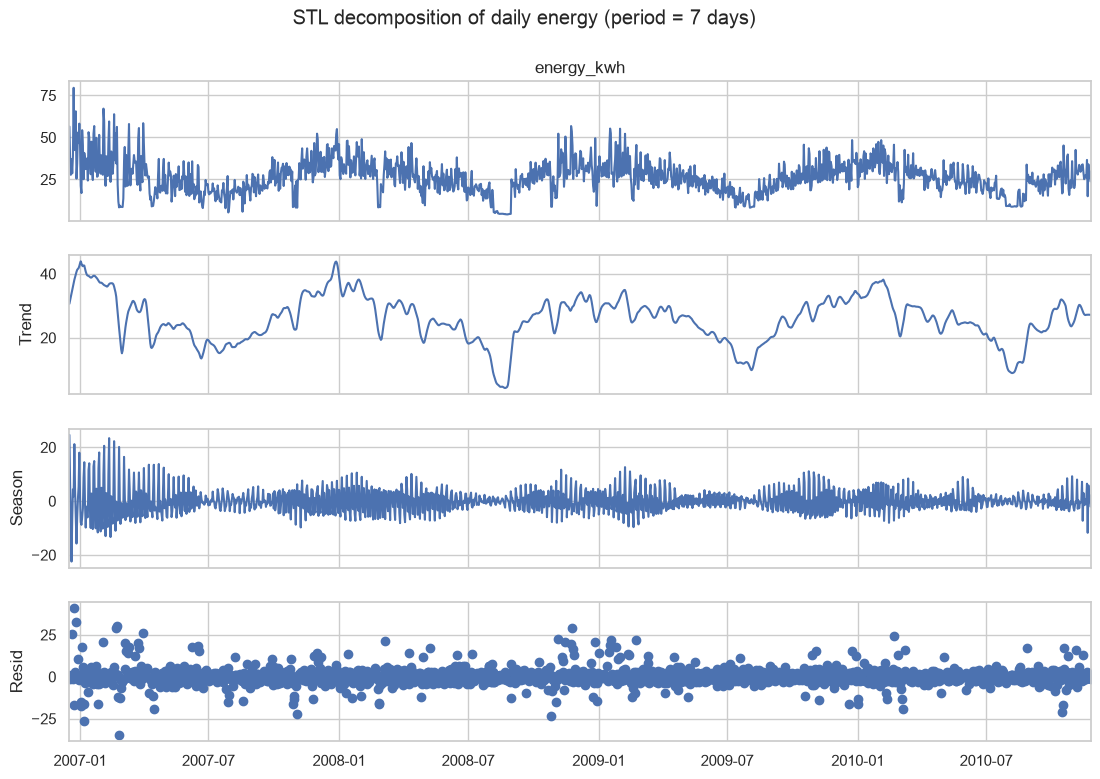

In [14]:
weekly_stl = timeseries.decompose_weekly(daily)
fig = viz.plot_decomposition(weekly_stl, "STL decomposition of daily energy (period = 7 days)", "06a_stl_weekly")

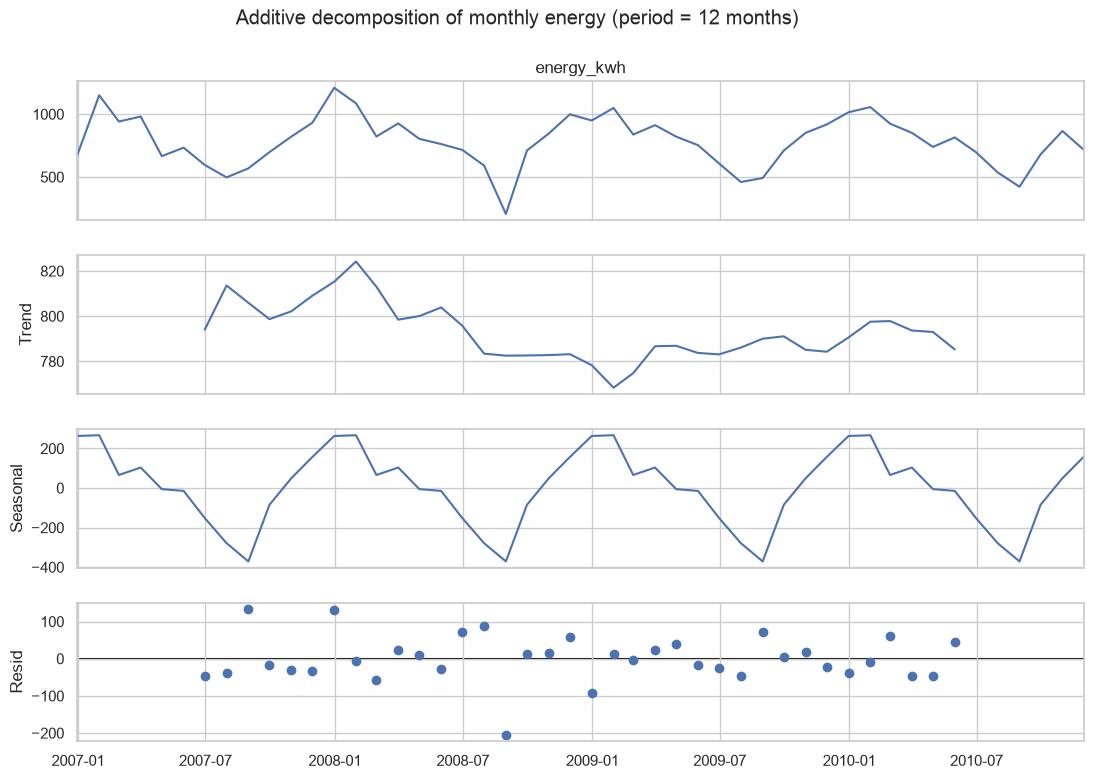

In [15]:
yearly = timeseries.decompose_yearly(daily)
fig = viz.plot_decomposition(yearly, "Additive decomposition of monthly energy (period = 12 months)", "06b_decomposition_yearly")

### 4.2 Пиковая нагрузка

Порог пика (95-й перцентиль): 2.861 кВт·ч за час, пиковых часов: 1730
Пики по дням недели:


,peak_hours
Mon,154
Tue,213
Wed,211
Thu,179
Fri,153
Sat,411
Sun,409


Топ-10 часов:


,kwh
datetime,
2008-11-23 18:00:00,6.561
2009-01-16 20:00:00,6.520
2008-02-02 19:00:00,6.496
2007-12-23 19:00:00,6.488
2007-02-22 21:00:00,6.364
2007-12-28 17:00:00,6.334
2008-11-23 20:00:00,6.311
2007-01-21 20:00:00,6.077
2008-01-26 19:00:00,6.014


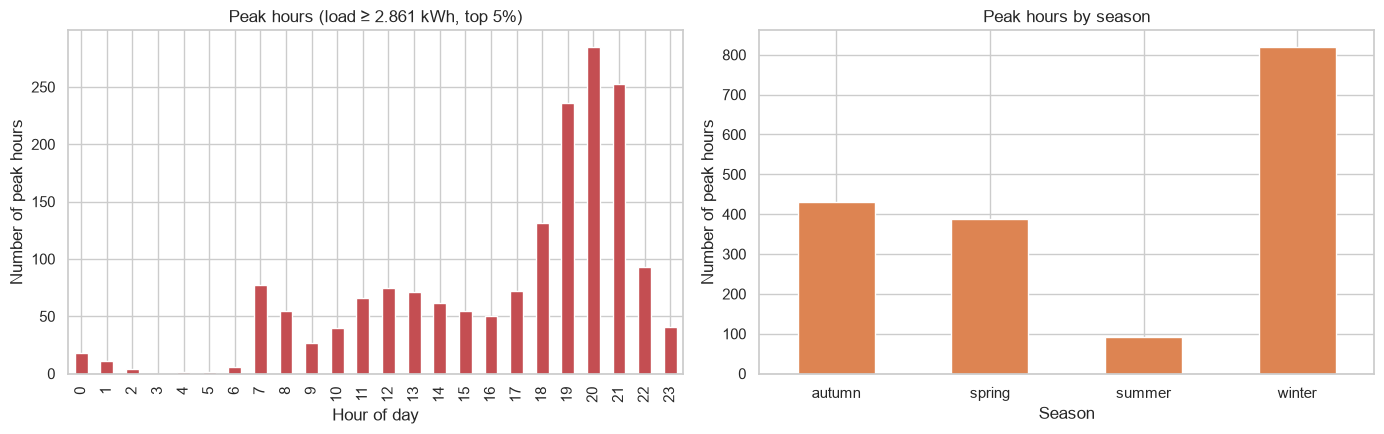

In [16]:
peaks = timeseries.peak_hours(hourly)
print(f"Порог пика (95-й перцентиль): {peaks['threshold_kwh']} кВт·ч за час, пиковых часов: {peaks['peak_count']}")
print("Пики по дням недели:"); display(peaks["by_weekday"].to_frame("peak_hours"))
print("Топ-10 часов:"); display(peaks["top_peaks"].to_frame("kwh"))
fig = viz.plot_peaks(peaks)

In [17]:
timeseries.sub_meter_shares(daily).to_frame('share_pct')

,share_pct
kitchen,6.18
laundry,7.15
water_heater_ac,35.55
other,51.12


## 5. Корреляционный анализ

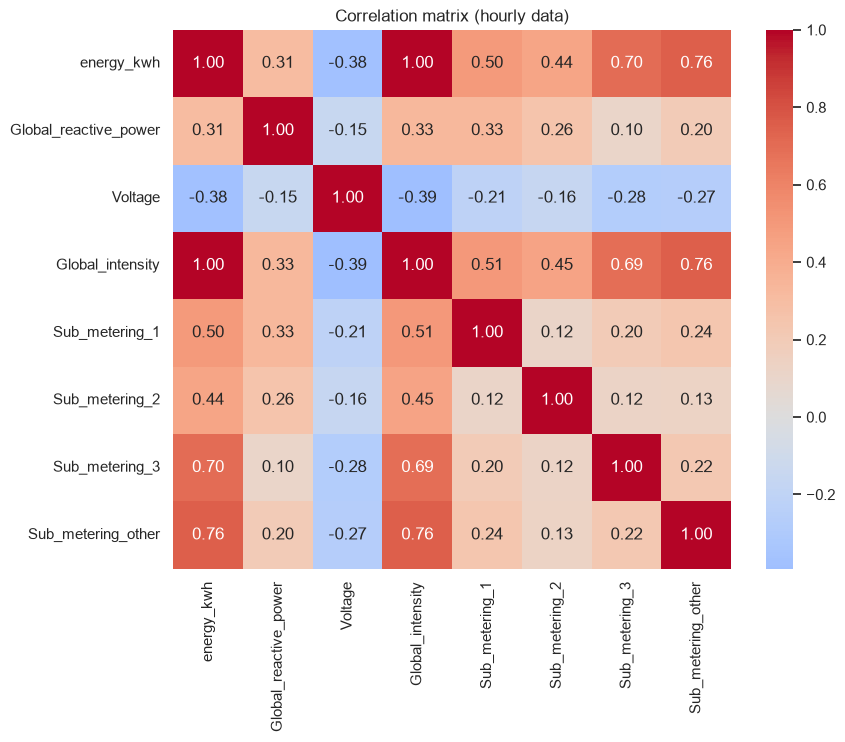

In [18]:
corr = timeseries.correlation_matrix(hourly)
fig = viz.plot_correlation(corr)

## 6. Интерактивные визуализации (Plotly)

In [19]:
viz.interactive_daily(daily)

In [20]:
viz.interactive_sub_meters(daily)

## 7. База данных SQLite

Очищенные почасовые данные загружаются в нормализованную схему:
`calendar` (измерение дат), `hourly_readings` (факты по часам), `sub_meters` (справочник подсчётчиков),
`sub_meter_readings` (связь «дата-час × подсчётчик»), `forecast_results` (результаты моделей).

```mermaid
erDiagram
    calendar ||--o{ hourly_readings : date_id
    calendar ||--o{ sub_meter_readings : date_id
    sub_meters ||--o{ sub_meter_readings : meter_id
    calendar {
        int date_id PK
        text date
        int year
        int month
        int weekday
        int is_weekend
        text season
    }
    hourly_readings {
        int reading_id PK
        int date_id FK
        int hour
        real energy_kwh
        real voltage
        real intensity
    }
    sub_meters {
        int meter_id PK
        text code
        text name
    }
    sub_meter_readings {
        int date_id FK
        int hour
        int meter_id FK
        real energy_wh
    }
    forecast_results {
        text model
        real mae
        real rmse
    }
```

In [21]:
counts = database.build_database(hourly)
pd.Series(counts, name="rows").to_frame()

,rows
calendar,1442
hourly_readings,34589
sub_meters,4
sub_meter_readings,138356


### 7.1 SQL-запросы (JOIN, GROUP BY/HAVING, подзапросы, CTE, оконные функции) → Pandas

In [22]:
sql_results = {}
for name, (title, sql) in database.QUERIES.items():
    sql_results[name] = database.run_query(name)
    display(Markdown(f"**{name}. {title}**"))
    display(Markdown(f"```sql\n{sql.strip()}\n```"))
    display(sql_results[name].head(12))

**1_monthly_energy_join. Monthly energy (kWh) per year — JOIN + GROUP BY**

```sql
SELECT c.year, c.month, ROUND(SUM(h.energy_kwh), 1) AS total_kwh
        FROM hourly_readings h
        JOIN calendar c ON c.date_id = h.date_id
        GROUP BY c.year, c.month
        ORDER BY c.year, c.month
```

,year,month,total_kwh
0,2006,12,698.8
1,2007,1,1150.3
2,2007,2,941.6
3,2007,3,981.0
4,2007,4,665.9
5,2007,5,733.5
6,2007,6,595.8
7,2007,7,496.6
8,2007,8,568.7
9,2007,9,698.0


**2_high_months_having. Months whose average daily consumption exceeds the overall average — HAVING + subquery**

```sql
SELECT c.year, c.month, ROUND(SUM(h.energy_kwh) / COUNT(DISTINCT c.date_id), 2) AS avg_daily_kwh
        FROM hourly_readings h
        JOIN calendar c ON c.date_id = h.date_id
        GROUP BY c.year, c.month
        HAVING SUM(h.energy_kwh) / COUNT(DISTINCT c.date_id) >
               (SELECT SUM(energy_kwh) / COUNT(DISTINCT date_id) FROM hourly_readings)
        ORDER BY avg_daily_kwh DESC
```

,year,month,avg_daily_kwh
0,2006,12,43.67
1,2007,12,39.04
2,2007,1,37.11
3,2008,1,35.04
4,2010,1,34.08
5,2009,1,33.85
6,2007,2,33.63
7,2008,11,33.30
8,2010,2,33.02
9,2009,12,32.75


... (20 outputs left out)

,hour,hours_above_avg,pct
0,0,405,28.1
1,1,360,25.0
2,2,325,22.6
3,3,313,21.7
4,4,337,23.4
5,5,344,23.9
6,6,620,43.0
7,7,756,52.5
8,8,767,53.2
9,9,877,60.9


**10_hourly_profile_ntile. Hour-of-day profile split into load quartiles — NTILE()**

```sql
WITH profile AS (
            SELECT hour, AVG(energy_kwh) AS avg_kwh
            FROM hourly_readings
            GROUP BY hour
        )
        SELECT hour, ROUND(avg_kwh, 3) AS avg_kwh,
               NTILE(4) OVER (ORDER BY avg_kwh) AS load_quartile
        FROM profile
        ORDER BY hour
```

,hour,avg_kwh,load_quartile
0,0,0.660,1
1,1,0.539,1
2,2,0.480,1
3,3,0.444,1
4,4,0.442,1
5,5,0.452,1
6,6,0.789,2
7,7,1.499,4
8,8,1.454,4
9,9,1.328,3


Результаты SQL используются в анализе — например, годовая динамика по месяцам (запрос 8, LAG):

In [23]:
yoy = sql_results["8_year_over_year_lag"].dropna()
yoy.pivot(index="month", columns="year", values="yoy_change_pct")

year,2008,2009,2010
month,,,
1,-5.6,-3.4,0.7
2,-12.7,1.9,10.3
3,-5.6,-1.5,-6.7
4,20.7,2.2,-9.9
5,3.9,-1.1,8.1
6,20.1,-15.1,14.9
7,19.1,-22.2,16.6
8,-63.8,139.1,-14.1
9,1.9,-0.1,-4.3


## 8. Прогноз: baseline vs методы

Задача — **прогноз суточного потребления на следующий день** (кВт·ч/день).
Хронологическое разбиение без перемешивания: train — 2006-12-17 … 2009-12-31, **test — 2010-01-01 … 2010-11-25**.

| Метод | Формула |
|---|---|
| Naive (**baseline**) | ŷ(t) = y(t−1) |
| Seasonal naive | ŷ(t) = y(t−7), тот же день недели |
| Moving average | ŷ(t) = среднее y(t−7 … t−1) |
| Linear regression | лаги 1, 2, 3, 7, 14 дней + скользящие средние 7 и 28 дней + дни недели + месяцы |

Признаки регрессии строятся только из прошлых значений (`shift`), модель обучается только на train → утечки нет.

In [24]:
metrics, predictions = pipeline.run_forecasts(daily)
metrics

,model,MAE,RMSE,MAPE_pct,MASE_vs_naive,fit_time_s,peak_memory_mb
0,Linear regression (lags),4.3938,5.8981,19.6142,0.8459,0.0295,0.8596
1,Moving average (7),4.3954,5.9276,19.1432,0.8462,0.0013,0.0477
2,Naive (baseline),5.1941,7.1200,20.7918,1.0000,0.0021,0.0565
3,Seasonal naive,5.8351,7.9377,25.7846,1.1234,0.0004,0.0240


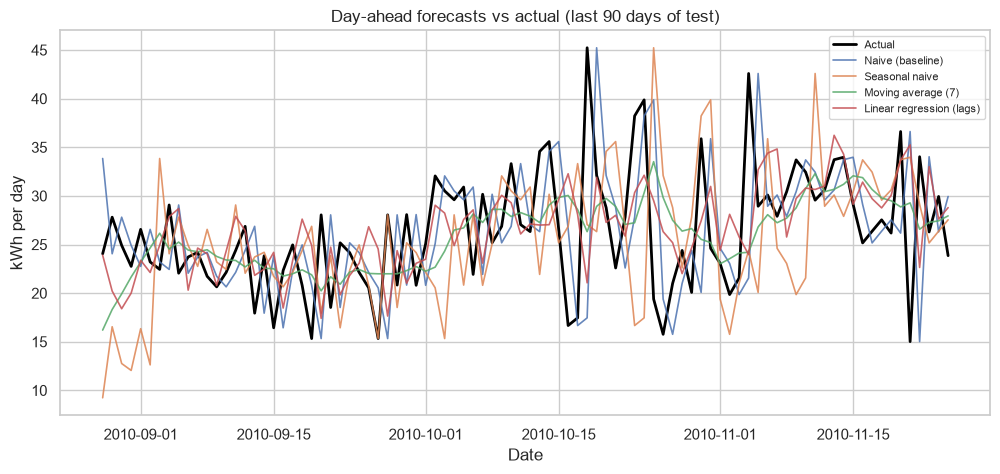

In [25]:
fig = viz.plot_forecasts(predictions)

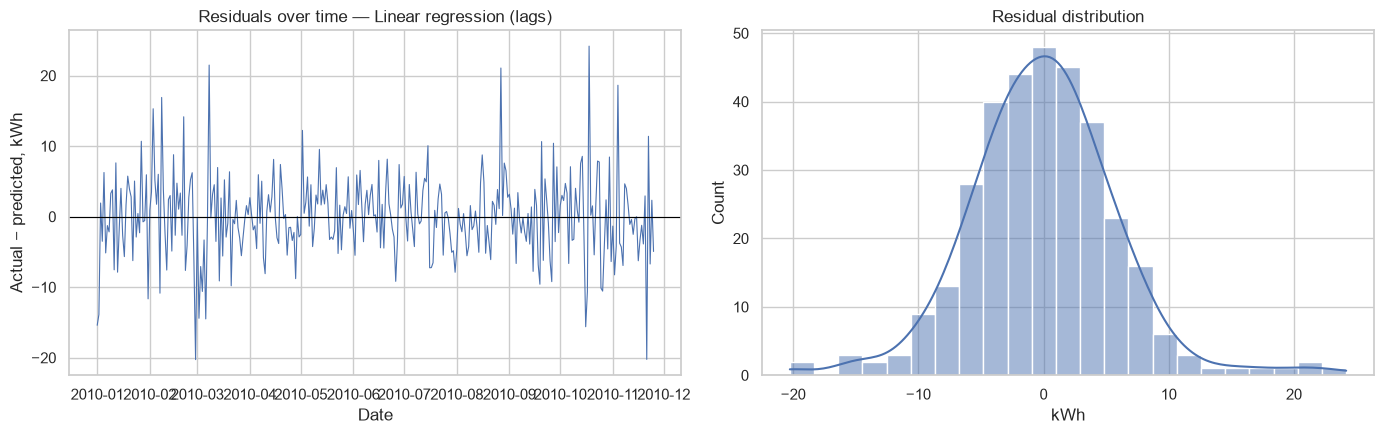

In [26]:
best_model = metrics.iloc[0]["model"]
fig = viz.plot_residuals(predictions, best_model)

### 8.1 Анализ ошибок по месяцам (MAE)

In [27]:
forecast.errors_by_period(predictions, best_model)

,Linear regression (lags),Naive (baseline),Seasonal naive,Moving average (7),best_model
datetime,,,,,
2010-01-31,4.975,7.295,6.294,5.355,Linear regression (lags)
2010-02-28,6.222,7.909,6.780,5.507,Moving average (7)
2010-03-31,4.900,6.252,8.404,5.670,Linear regression (lags)
2010-04-30,3.223,3.670,4.378,3.015,Moving average (7)
2010-05-31,3.319,5.061,4.897,4.116,Linear regression (lags)
2010-06-30,3.407,4.437,3.445,4.006,Linear regression (lags)
2010-07-31,3.678,2.697,5.092,3.664,Naive (baseline)
2010-08-31,3.747,2.696,5.076,3.389,Naive (baseline)
2010-09-30,4.204,4.903,4.384,3.147,Moving average (7)


### 8.2 Расширение: почасовой прогноз (на 1 час вперёд)

Те же подходы на почасовом ряду: сезонность 24 ч, лаги 1, 2, 3, 24, 168 ч, скользящее среднее за 24 ч.

In [28]:
hourly_metrics, hourly_predictions = forecast.compare_models(hourly["energy_kwh"].astype("float64"), forecast.HOURLY_SETUP)
hourly_metrics

,model,MAE,RMSE,MAPE_pct,MASE_vs_naive,fit_time_s,peak_memory_mb
0,Linear regression (lags),0.3630,0.5092,47.8012,0.8915,0.0390,32.7214
1,Naive (baseline),0.4072,0.6190,45.2904,1.0000,0.0009,1.4587
2,Seasonal naive,0.5538,0.8185,68.2240,1.3602,0.0004,0.4504
3,Moving average (24),0.5815,0.7422,87.8473,1.4282,0.0009,1.0593


### 8.3 Прогноз на будущее (рекурсивно, линейная регрессия на всей истории)

In [29]:
forecast.forecast_future(daily['energy_kwh'].astype('float64'), 7).round(2).to_frame('forecast_kwh')

,forecast_kwh
datetime,
2010-11-26,27.97
2010-11-27,33.99
2010-11-28,31.96
2010-11-29,28.83
2010-11-30,30.10
2010-12-01,31.70
2010-12-02,29.54


## 9. Выводы

**Данные и предобработка**
- 2 075 259 минутных записей за 47 месяцев; 1,25 % пропусков, все признаки пропущены одновременно (сбой счётчика).
  Пропуски сконцентрированы в 2010 году (3,7 %), самый длинный — 120 ч (17–22.08.2010).
- Оптимизация типов (`float32`, `datetime64`) уменьшила память фрейма **с 239 до 71 МБ (в 3,4 раза)**.
  Parquet занимает **22 МБ против 127 МБ CSV** (в 5,8 раза меньше) и читается за **≈0,1 с против ≈2 с** у чанкового CSV
  при пиковой памяти процесса ≈250–300 МБ против ≈600 МБ у наивного чтения (точные значения — в таблице 1.1). Итог: сырые данные один раз читаем чанками, дальше работаем с Parquet.

**Паттерны потребления**
- Среднее потребление — **26,1 кВт·ч/день**. Два пика в будни: утренний (7–8 ч, ≈1,7 кВт·ч/ч) и вечерний (20–21 ч, ≈1,85 кВт·ч/ч);
  ночной минимум 3–5 ч (≈0,42). В выходные утреннего пика нет, нагрузка высокая весь день с максимумом 19–20 ч (≈2,0).
- **Выходные** дают 47 % всех пиковых часов (Сб 411, Вс 409 против 150–210 в будни).
- **Сезонность сильная**: зима 34,0 кВт·ч/день против лета 17,4 — почти в 2 раза; 47 % пиковых часов приходятся на зиму, лишь 5 % — на лето.
  В августе заметен провал (отпуск). STL с периодом 7 дней показывает недельную компоненту, но она слабее суточного шума.
- Годовой тренд слабо снижается: 26,8 (2007) → 25,3 кВт·ч/день (2010); по SQL-запросу с `LAG` январь: −5,6 % (2008), −3,4 % (2009).
- Структура: бойлер и кондиционер — 35,5 %, кухня — 6,2 %, прачечная — 7,2 %, **51 % энергии не покрыт подсчётчиками** (отопление, свет, электроника).
- Корреляции: энергия ≈ сила тока (r = 0,999, т.к. P = U·I); с напряжением обратная связь (r = −0,38) — при большой нагрузке напряжение проседает.

**Прогноз (test — 2010 год, 329 дней)**

| Модель | MAE, кВт·ч/день | Улучшение к baseline |
|---|---|---|
| Linear regression (лаги) | 4,39 | −15,4 % |
| Moving average (7) | 4,40 | −15,4 % |
| Naive (baseline) | 5,19 | — |
| Seasonal naive (7) | 5,84 | +12,3 % (хуже) |

- Обе модели обходят baseline примерно на 15 %. Seasonal naive хуже naive: недельная сезонность слабее изменчивости день ко дню.
- Летом (июль–август) лучший — naive: потребление низкое и стабильное, сглаживание только запаздывает. Зимой и осенью выигрывает регрессия.
- На почасовом ряду регрессия даёт MAE 0,363 против 0,407 у naive (−11 %); скользящее среднее за 24 ч там хуже baseline — оно стирает суточный профиль.
- **Выбор подхода:** по качеству регрессия и скользящее среднее почти равны, но MA не требует обучения и в десятки раз быстрее.
  Для суточного прогноза достаточно MA(7); регрессию стоит выбирать, когда нужны внешние признаки (температура, праздники) и почасовой прогноз.

**Ограничения:** один дом; нет данных о погоде; длинные пропуски 2010 года заполнены значениями предыдущей недели, что немного занижает ошибку naive-моделей в эти дни;
рекурсивный прогноз на несколько дней накапливает ошибку.

## Вклад участников

| Участник | Вклад |
|---|---|
| Rabat Karabek | _заполнить_ |
| Nurmukhanbet Sanzhar | _заполнить_ |
| Ussurbayeva Inkar | _заполнить_ |